# 02 - Descriptive trends

This notebook answers **RQ3 only**: how PM2.5 and asthma ED rates changed over 2015-2023, and which neighborhoods have the highest and lowest averages.

The PM2.5 yearly mean is the unweighted average across the 42 UHF42 neighborhoods. Adult asthma ED rates are missing in 2015 at the source, so the adult trend and averages begin in 2016.

No PM2.5-asthma correlation or regression is computed here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

panel_path = Path("data/clean/uhf42_panel.csv")
if not panel_path.is_file():
    panel_path = Path("../data/clean/uhf42_panel.csv")

panel = pd.read_csv(panel_path)
panel.shape

(378, 14)

## PM2.5 trend

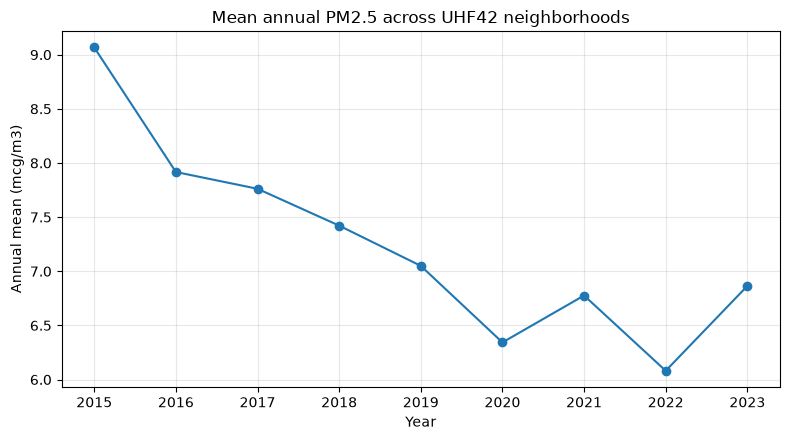

In [2]:
pm25_by_year = panel.groupby("year")["pm25_annual"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pm25_by_year.index, pm25_by_year.values, marker="o")
ax.set_title("Mean annual PM2.5 across UHF42 neighborhoods")
ax.set_xlabel("Year")
ax.set_ylabel("Annual mean (mcg/m3)")
ax.set_xticks(pm25_by_year.index)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### What I notice



## Child asthma ED rate trend

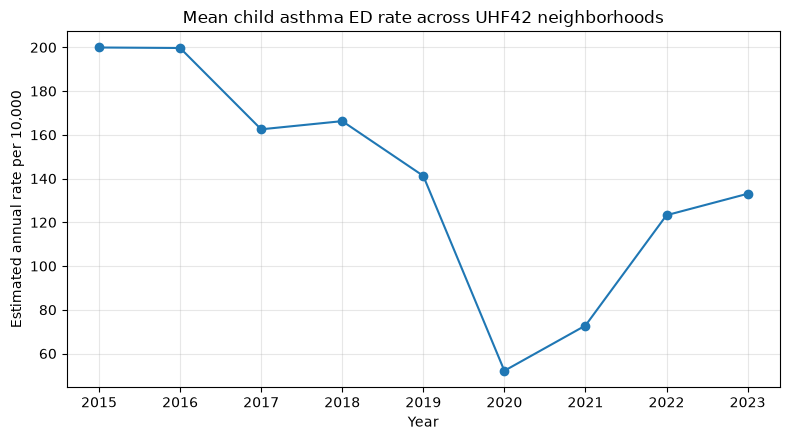

In [3]:
child_rate_by_year = panel.groupby("year")["asthma_child_rate"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(child_rate_by_year.index, child_rate_by_year.values, marker="o")
ax.set_title("Mean child asthma ED rate across UHF42 neighborhoods")
ax.set_xlabel("Year")
ax.set_ylabel("Estimated annual rate per 10,000")
ax.set_xticks(child_rate_by_year.index)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### What I notice



## Adult asthma ED rate trend

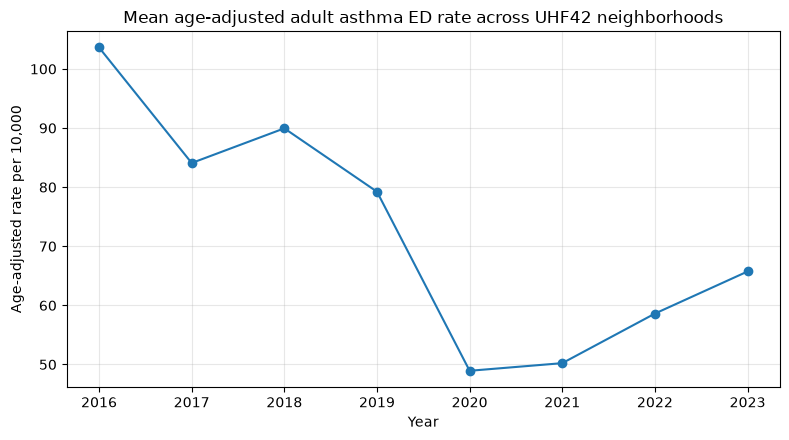

In [4]:
adult_rate_by_year = panel.groupby("year")["asthma_adult_rate_adj"].mean().dropna()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(adult_rate_by_year.index, adult_rate_by_year.values, marker="o")
ax.set_title("Mean age-adjusted adult asthma ED rate across UHF42 neighborhoods")
ax.set_xlabel("Year")
ax.set_ylabel("Age-adjusted rate per 10,000")
ax.set_xticks(adult_rate_by_year.index)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### What I notice



## Neighborhood averages

Each table ranks neighborhoods by the mean of the measure across all available years. Adult averages use 2016-2023 because adult asthma data are missing for 2015.

In [5]:
def show_extremes(measure):
    means = panel.groupby("neighborhood")[measure].mean()
    highest = means.nlargest(5).rename_axis("Neighborhood").reset_index(name="Mean")
    lowest = means.nsmallest(5).rename_axis("Neighborhood").reset_index(name="Mean")
    highest.columns = ["Highest 5 neighborhoods", "Mean"]
    lowest.columns = ["Lowest 5 neighborhoods", "Mean"]
    display(pd.concat([highest, lowest], axis=1))

### PM2.5 annual mean

In [6]:
show_extremes("pm25_annual")

,Highest 5 neighborhoods,Mean,Lowest 5 neighborhoods,Mean
0,Gramercy Park - Murray Hill,9.477778,Rockaways,5.944444
1,Chelsea - Clinton,9.466667,South Beach - Tottenville,6.100000
2,Greenwich Village - SoHo,8.866667,Stapleton - St. George,6.355556
3,Lower Manhattan,8.388889,Southeast Queens,6.377778
4,Union Square - Lower East Side,8.355556,Coney Island - Sheepshead Bay,6.411111


### Child asthma ED rate

In [7]:
show_extremes("asthma_child_rate")

,Highest 5 neighborhoods,Mean,Lowest 5 neighborhoods,Mean
0,East Harlem,396.055556,Bayside - Little Neck,25.377778
1,Central Harlem - Morningside Heights,375.211111,South Beach - Tottenville,25.422222
2,Hunts Point - Mott Haven,342.944444,Greenwich Village - SoHo,26.755556
3,High Bridge - Morrisania,329.033333,Borough Park,27.100000
4,Crotona - Tremont,293.144444,Bensonhurst - Bay Ridge,31.622222


### Adult asthma ED age-adjusted rate

In [8]:
show_extremes("asthma_adult_rate_adj")

,Highest 5 neighborhoods,Mean,Lowest 5 neighborhoods,Mean
0,Hunts Point - Mott Haven,216.9875,Greenwich Village - SoHo,11.3875
1,East Harlem,215.1250,Bayside - Little Neck,11.9250
2,High Bridge - Morrisania,199.5750,Upper East Side,16.2250
3,Central Harlem - Morningside Heights,184.2000,Bensonhurst - Bay Ridge,16.9125
4,Crotona - Tremont,181.9750,Flushing - Clearview,17.5625
